In [2]:
!pip install seaborn

# Import all tools we need
import pandas as pd          # for handling tables (our dataset)
import numpy as np           # for number operations
import matplotlib.pyplot as plt  # for drawing charts
import seaborn as sns        # for prettier charts
from sklearn.preprocessing import LabelEncoder, StandardScaler  # for encoding and scaling

print("All libraries loaded successfully!")

All libraries loaded successfully!


In [5]:
# Upload your kaggle.json file
from google.colab import files

# Remove any existing kaggle.json files to ensure the new upload is named correctly
!rm -f kaggle.json
!rm -f "kaggle (1).json"

files.upload()  # select your kaggle.json when prompted

# Put it in the right place so Kaggle API can find it
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Now download the dataset
!kaggle datasets download -d iamsouvik/software-requirements-dataset --unzip

print("Dataset downloaded!")

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/iamsouvik/software-requirements-dataset
License(s): unknown
100% 21.3k/21.3k [00:00<00:00, 47.8MB/s]

Dataset downloaded!


In [11]:
# Load the dataset as a plain text file and parse each line
import pandas as pd

requirements = []
with open('nfr.txt', 'r') as f:
    for line in f:
        parts = line.strip().split(':', 1) # Split only on the first colon
        if len(parts) == 2:
            req_type = parts[0].strip()
            req_description = parts[1].strip()
            requirements.append({'Type': req_type, 'Description': req_description})

df = pd.DataFrame(requirements)

# Look at the first 5 rows
print("First 5 rows:")
print(df.head())

# How many rows and columns?
print("\nShape (rows, columns):", df.shape)

# What are the column names and data types?
print("\nColumn info:")
print(df.info())

# How many missing values in each column?
print("\nMissing values:")
print(df.isnull().sum())

First 5 rows:
  Type                                        Description
0   PE  The system shall refresh the display every 60 ...
1   LF  The application shall match the color of the s...
2   US  If projected  the data must be readable.  On a...
3    A  The product shall be available during normal b...
4   US  If projected  the data must be understandable....

Shape (rows, columns): (556, 2)

Column info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 556 entries, 0 to 555
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Type         556 non-null    object
 1   Description  556 non-null    object
dtypes: object(2)
memory usage: 8.8+ KB
None

Missing values:
Type           0
Description    0
dtype: int64


In [15]:
# For text columns — fill missing values with 'Unknown'
df['Description'] = df['Description'].fillna('Unknown')

# For any number columns — fill with the median (middle value)
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Confirm no more missing values
print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
Type           0
Description    0
dtype: int64


In [16]:
# See what unique categories exist
print("Unique requirement types:", df['Type'].unique())

# Convert text labels to numbers
le = LabelEncoder()
df['Type_encoded'] = le.fit_transform(df['Type'])

print("\nEncoding mapping:")
for i, label in enumerate(le.classes_):
    print(f"  {label} → {i}")

print("\nSample after encoding:")
print(df[['Type', 'Type_encoded']].head(10))

Unique requirement types: ['PE' 'LF' 'US' 'A' 'SE' 'F' 'L' 'O' 'PO' 'SC' 'FT' 'MN']

Encoding mapping:
  A → 0
  F → 1
  FT → 2
  L → 3
  LF → 4
  MN → 5
  O → 6
  PE → 7
  PO → 8
  SC → 9
  SE → 10
  US → 11

Sample after encoding:
  Type  Type_encoded
0   PE             7
1   LF             4
2   US            11
3    A             0
4   US            11
5   SE            10
6   US            11
7   PE             7
8    F             1
9    F             1


In [18]:
# Add a column: length of each requirement text (this is our numerical feature)
df['requirement_length'] = df['Description'].apply(len)

# Normalize it using StandardScaler (mean=0, spread=1)
scaler = StandardScaler()
df['requirement_length_scaled'] = scaler.fit_transform(df[['requirement_length']])

print("Before scaling:")
print(df['requirement_length'].describe())

print("\nAfter scaling:")
print(df['requirement_length_scaled'].describe())

Before scaling:
count    556.000000
mean     116.424460
std       60.474279
min       37.000000
25%       75.000000
50%      102.000000
75%      138.000000
max      517.000000
Name: requirement_length, dtype: float64

After scaling:
count    5.560000e+02
mean    -5.750796e-17
std      1.000900e+00
min     -1.314542e+00
25%     -6.856099e-01
50%     -2.387370e-01
75%      3.570934e-01
max      6.629864e+00
Name: requirement_length_scaled, dtype: float64


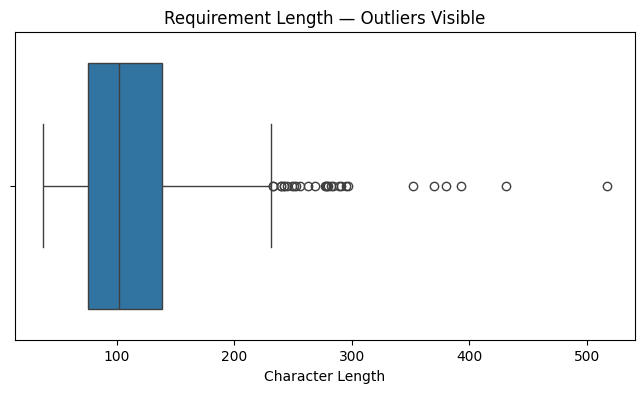

Rows before removing outliers: 556
Rows after removing outliers: 527


In [19]:
# Draw a boxplot to SEE the outliers
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['requirement_length'])
plt.title('Requirement Length — Outliers Visible')
plt.xlabel('Character Length')
plt.show()

# Remove outliers using IQR method
Q1 = df['requirement_length'].quantile(0.25)
Q3 = df['requirement_length'].quantile(0.75)
IQR = Q3 - Q1

# Keep only rows within acceptable range
df_clean = df[
    (df['requirement_length'] >= Q1 - 1.5 * IQR) &
    (df['requirement_length'] <= Q3 + 1.5 * IQR)
]

print(f"Rows before removing outliers: {len(df)}")
print(f"Rows after removing outliers: {len(df_clean)}")

In [20]:
# Save cleaned dataset
df_clean.to_csv('software_requirements_cleaned.csv', index=False)
print("Clean dataset saved!")

# Final look at what we built
print("\nFinal cleaned dataset:")
print(df_clean.head())
print("\nShape:", df_clean.shape)

Clean dataset saved!

Final cleaned dataset:
  Type                                        Description  Type_encoded  \
0   PE  The system shall refresh the display every 60 ...             7   
1   LF  The application shall match the color of the s...             4   
2   US  If projected  the data must be readable.  On a...            11   
3    A  The product shall be available during normal b...             0   
4   US  If projected  the data must be understandable....            11   

   requirement_length  requirement_length_scaled  
0                  54                  -1.033178  
1                  96                  -0.338042  
2                 159                   0.704661  
3                 196                   1.317043  
4                 203                   1.432898  

Shape: (527, 5)


In [21]:
# Download the cleaned file to your computer
from google.colab import files
files.download('software_requirements_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>